In [4]:
import pandas as pd
print("done")

done


In [2]:
import os
print(os.listdir("../data"))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [3]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")
items = pd.read_csv("../data/olist_order_items_dataset.csv")
customers = pd.read_csv("../data/olist_customers_dataset.csv")
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")

print(orders.shape, items.shape, customers.shape, reviews.shape)

(99441, 8) (112650, 7) (99441, 5) (99224, 7)


In [5]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [6]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [8]:
orders.groupby("order_status")["order_delivered_customer_date"].apply(lambda x: x.isna().sum())

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

In [9]:
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["order_delivered_customer_date"])

print(delivered.shape)


(96470, 8)


In [10]:
delivered["delivery_days"] = (delivered["order_delivered_customer_date"]
                              - delivered["order_purchase_timestamp"]).dt.days

delivered["is_late"] = (delivered["order_delivered_customer_date"]
                        > delivered["order_estimated_delivery_date"])

delivered[["delivery_days", "is_late"]].describe(include="all")

,delivery_days,is_late
count,96470.000000,96470
unique,NaN,2
top,NaN,False
freq,NaN,88644
mean,12.093604,NaN
std,9.551380,NaN
min,0.000000,NaN
25%,6.000000,NaN
50%,10.000000,NaN
75%,15.000000,NaN


In [11]:
delivered["is_late"].mean() * 100

8.112366538820359

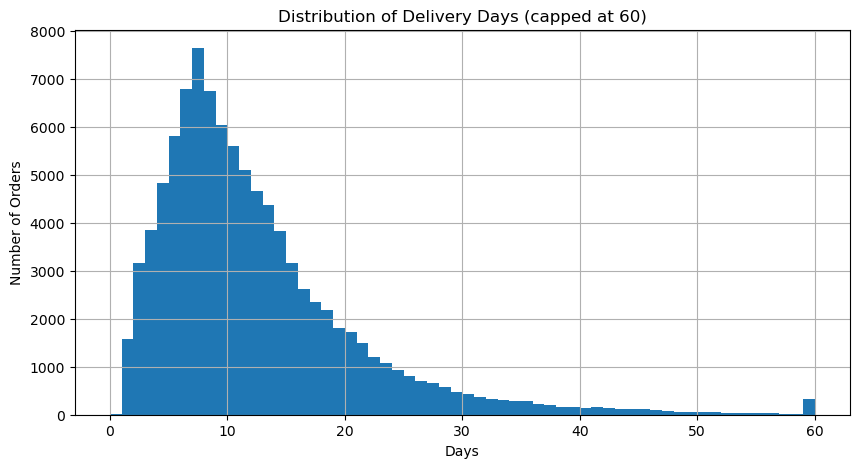

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
delivered["delivery_days"].clip(upper=60).hist(bins=60)
plt.title("Distribution of Delivery Days (capped at 60)")
plt.xlabel("Days")
plt.ylabel("Number of Orders")
plt.show()

In [13]:
(delivered["delivery_days"] > 60).sum()

288

In [14]:
df = (delivered
      .merge(customers[["customer_id", "customer_unique_id", "customer_state"]],
             on="customer_id", how="left")
      .merge(items.groupby("order_id").agg(price=("price", "sum"),
                                           freight=("freight_value", "sum"),
                                           n_items=("order_item_id", "count")).reset_index(),
             on="order_id", how="left"))

print(df.shape)
df.head()

(96470, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,customer_unique_id,customer_state,price,freight,n_items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8,False,7c396fd4830fd04220f754e42b4e5bff,SP,29.99,8.72,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13,False,af07308b275d755c9edb36a90c618231,BA,118.70,22.76,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9,False,3a653a41f6f9fc3d2a113cf8398680e8,GO,159.90,19.22,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13,False,7c142cf63193a1473d2e66489a9ae977,RN,45.00,27.20,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2,False,72632f0f9dd73dfee390c9b22eb56dd6,SP,19.90,8.72,1


In [15]:
print(df.shape)

(96470, 15)


In [16]:
print(reviews.shape[0], reviews["order_id"].nunique())

99224 98673


In [17]:
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews_clean = (reviews
                 .sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last")
                 [["order_id", "review_score"]])

In [18]:
df = df.merge(reviews_clean, on="order_id", how="left")

print(df.shape)
print(df["review_score"].isna().sum())

(96470, 16)
646


In [19]:
df.groupby("is_late")["review_score"].agg(["mean", "count"])

,mean,count
is_late,,
False,4.294114,88163
True,2.565070,7661


In [20]:
df.to_csv("../data/clean_orders.csv", index=False)

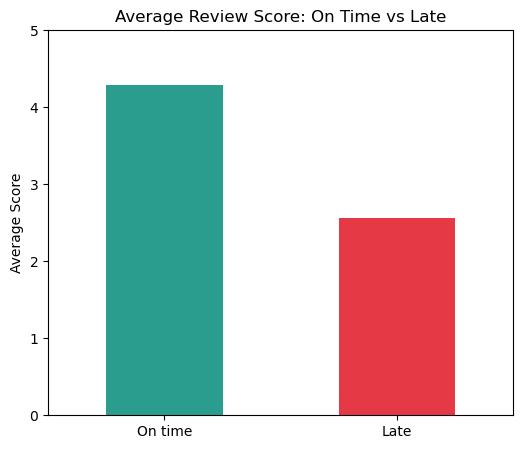

In [21]:
import matplotlib.pyplot as plt

avg = df.groupby("is_late")["review_score"].mean()
avg.index = ["On time", "Late"]

plt.figure(figsize=(6, 5))
avg.plot(kind="bar", color=["#2a9d8f", "#e63946"])
plt.title("Average Review Score: On Time vs Late")
plt.ylabel("Average Score")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

In [22]:
(df.groupby("is_late")["review_score"]
   .value_counts(normalize=True)
   .unstack() * 100).round(1)

review_score,1.0,2.0,3.0,4.0,5.0
is_late,,,,,
False,6.6,2.6,8.0,20.4,62.4
True,46.2,7.9,11.4,12.3,22.2


In [23]:
df.to_csv("../data/clean_orders.csv", index=False)

In [24]:
state = (df.groupby("customer_state")
           .agg(orders=("order_id", "count"),
                late_pct=("is_late", lambda x: x.mean() * 100),
                avg_days=("delivery_days", "mean"),
                avg_score=("review_score", "mean"))
           .round(1))

state = state[state["orders"] >= 500].sort_values("late_pct", ascending=False)
state.head(10)

,orders,late_pct,avg_days,avg_score
customer_state,,,,
MA,717,19.7,21.1,3.8
CE,1279,15.3,20.8,3.9
BA,3256,14.0,18.9,3.9
RJ,12350,13.5,14.8,4.0
PA,946,12.4,23.3,3.9
ES,1995,12.2,15.3,4.1
MS,701,11.6,15.2,4.2
PB,517,11.0,20.0,4.1
PE,1593,10.8,18.0,4.1


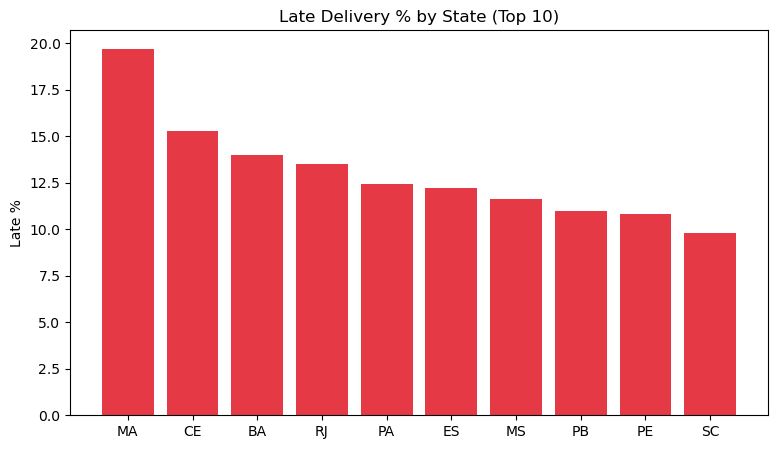

In [29]:
top = state.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top.index, top["late_pct"], color="#e63946")
plt.title("Late Delivery % by State (Top 10)")
plt.ylabel("Late %")
plt.savefig("../images/late_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
state[["late_pct", "avg_score"]].corr()

,late_pct,avg_score
late_pct,1.000000,-0.856254
avg_score,-0.856254,1.000000


In [27]:
state["late_orders"] = (state["orders"] * state["late_pct"] / 100).round()
state.sort_values("late_orders", ascending=False).head(10)

,orders,late_pct,avg_days,avg_score,late_orders
customer_state,,,,,
SP,40494,5.9,8.3,4.2,2389.0
RJ,12350,13.5,14.8,4.0,1667.0
MG,11354,5.6,11.5,4.2,636.0
BA,3256,14.0,18.9,3.9,456.0
RS,5344,7.1,14.8,4.2,379.0
SC,3546,9.8,14.5,4.1,348.0
PR,4923,5.0,11.5,4.2,246.0
ES,1995,12.2,15.3,4.1,243.0
CE,1279,15.3,20.8,3.9,196.0


In [28]:
state.sort_values("orders", ascending=False).head(5)

,orders,late_pct,avg_days,avg_score,late_orders
customer_state,,,,,
SP,40494,5.9,8.3,4.2,2389.0
RJ,12350,13.5,14.8,4.0,1667.0
MG,11354,5.6,11.5,4.2,636.0
RS,5344,7.1,14.8,4.2,379.0
PR,4923,5.0,11.5,4.2,246.0


In [31]:
df.to_csv("../data/clean_orders.csv", index=False)

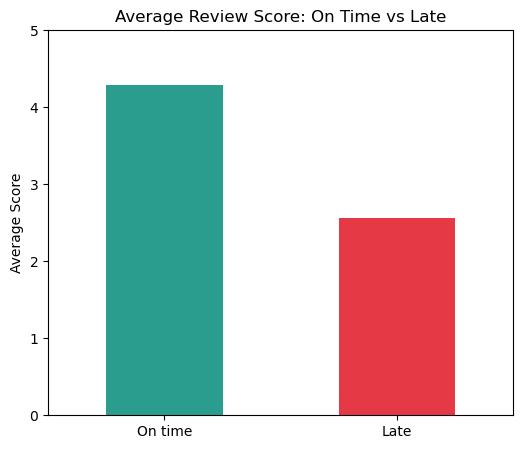

In [32]:
avg = df.groupby("is_late")["review_score"].mean()
avg.index = ["On time", "Late"]

plt.figure(figsize=(6, 5))
avg.plot(kind="bar", color=["#2a9d8f", "#e63946"])
plt.title("Average Review Score: On Time vs Late")
plt.ylabel("Average Score")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.savefig("../images/review_on_time_vs_late.png", dpi=150, bbox_inches="tight")
plt.show()
